# Hologram of multiple spheres

This notebook shows how to compute the hologram of several dielectric spheres
in the field of view at the same time.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from pylorenzmie.theory import Cluster, LorenzMie, Sphere

plt.rcParams['figure.dpi'] = 72

The **LorenzMie** calculator combines the instrument that illuminates the sample,
collects the light and magnifies it with the particle that scatters the light.
We give it the pixel coordinates at which to compute the hologram: a 640×480
camera frame.

In [2]:
shape = (480, 640)                       # (rows, columns)
model = LorenzMie()
model.coordinates = model.meshgrid(shape)
print(type(model).__name__, '|', model.instrument)

numbaLorenzMie | Instrument(wavelength=0.447, magnification=0.048, noise=0.05, n_m=1.34)


The particle that scatters the light can be a **Cluster**: a list of spheres, or
other particles, each with its own size, refractive index and position. The
cluster has a position of its own, which is the origin of the coordinates of
the spheres in it, so the sphere positions are relative to the cluster. By
default that origin is 100 pixels from the focal plane. Here we put it at the
origin of the image coordinates and the focal plane, so that the sphere
positions mean what they usually do.

We create a sample with five spheres and move each to a distinct location. The
$z_p$ coordinate is the distance from the focal plane, in pixels.

In [3]:
spheres = [Sphere(a_p=0.75, n_p=1.45) for _ in range(5)]
for sphere, (x, z) in zip(spheres, [(100, 100), (200, 150), (300, 200),
                                    (400, 250), (500, 300)]):
    sphere.r_p = [x, 240, z]

model.particle = Cluster(particles=spheres, x_p=0., y_p=0., z_p=0.)

Having defined the scene, we compute and display the hologram. The fringes of
each sphere grow with its distance from the focal plane, and where they overlap
the fields add coherently.

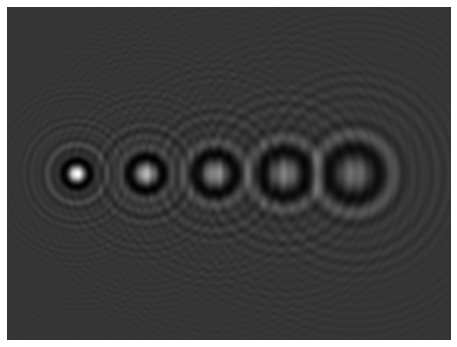

In [4]:
hologram = model.hologram().reshape(shape)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(hologram, cmap='gray')
ax.axis('off')
plt.show()

## Speed

`pylorenzmie.theory.LorenzMie` is the fastest calculator that is available:
`numbaLorenzMie` if Numba is installed, which uses all of the CPU's cores, and
the plain NumPy calculator otherwise. You can see which one you have from the
type printed above. The hologram of this 307,200-pixel frame takes:

In [5]:
%timeit model.hologram()

49 ms ± 3.97 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


A GPU calculator can be faster for large frames. See the Quickstart for how to
choose one.